
# Edge AI Assignment: Neural Network from Scratch (Checkerboard Classification)

## Objective
Build a simple neural network **from scratch (no ML libraries)** to classify a 2D checkerboard pattern.

You will:
- Implement forward propagation
- Implement backpropagation
- Train a small neural network
- Visualize the decision boundary

---

## Dataset Concept
We generate (x, y) points and assign labels based on a checkerboard pattern.

This is a **non-linear classification problem** (like XOR, but extended to 2D).


In [1]:

import numpy as np
import matplotlib.pyplot as plt


## Step 1: Generate Checkerboard Data

In [2]:

def generate_data(n_samples=500, k=4):
    X = np.random.uniform(-1, 1, (n_samples, 2))

    # Checkerboard labels
    y = ((np.floor((X[:,0]+1)*k) + np.floor((X[:,1]+1)*k)) % 2)

    return X, y.reshape(-1, 1)

X, y = generate_data()

## Visualize Dataset

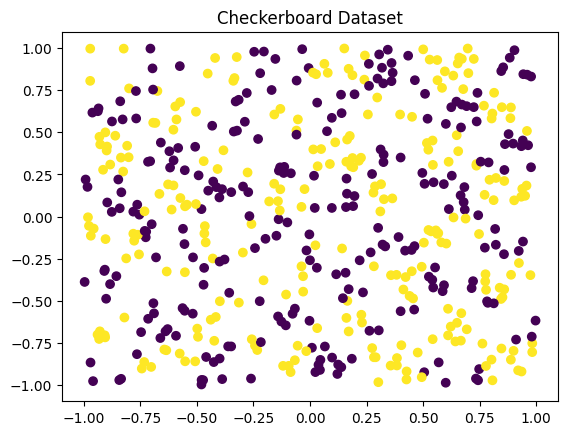

In [3]:

plt.scatter(X[:,0], X[:,1], c=y.flatten())
plt.title("Checkerboard Dataset")
plt.show()



## Step 2: Build Neural Network

Architecture:
- Input: 2 neurons (x, y)
- Hidden: YOU DECIDE
- Output: 1 neuron (sigmoid)

Fill in missing parts.


In [4]:

# Initialize weights
def init_params(input_size, hidden_size, output_size):
    # He initialization for ReLU
    W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
    b1 = np.zeros((1, hidden_size))

    W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
    b2 = np.zeros((1, output_size))

    return W1, b1, W2, b2

## Activation Functions

In [5]:

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)


## Forward Pass

In [6]:
def forward(X, W1, b1, W2, b2):
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)  # Hidden layer with ReLU

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)  # Output layer with sigmoid for binary classification

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

## Loss Function

In [7]:

def compute_loss(y_true, y_pred):
    # Binary cross-entropy
    m = y_true.shape[0]
    y_pred = np.clip(y_pred, 1e-8, 1 - 1e-8)
    loss = -(1 / m) * np.sum(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return loss


## Backpropagation

In [8]:
def backward(X, y, W1, b1, W2, b2, cache):
    m = X.shape[0]
    A1 = cache["A1"]
    A2 = cache["A2"]
    Z1 = cache["Z1"]

    dZ2 = A2 - y
    dW2 = (1 / m) * np.dot(A1.T, dZ2)
    db2 = (1 / m) * np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients using ReLU derivative
    dZ1 = np.dot(dZ2, W2.T) * relu_derivative(Z1)
    dW1 = (1 / m) * np.dot(X.T, dZ1)
    db1 = (1 / m) * np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

## Training Loop

In [9]:

def train(X, y, hidden_size=32, lr=0.1, epochs=25000):
    W1, b1, W2, b2 = init_params(2, hidden_size, 1)

    for epoch in range(epochs):
        # Forward
        y_pred, cache = forward(X, W1, b1, W2, b2)

        # Loss
        loss = compute_loss(y, y_pred)

        # Backward
        dW1, db1, dW2, db2 = backward(X, y, W1, b1, W2, b2, cache)

        # Optional: Clip gradients to prevent explosion/stagnation
        dW1 = np.clip(dW1, -5, 5)
        dW2 = np.clip(dW2, -5, 5)

        # Update weights (Gradient Descent)
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

        if epoch % 1000 == 0:
            print(f"Epoch {epoch}, Loss: {loss:.4f}")

    return W1, b1, W2, b2

## Visualize Decision Boundary

In [10]:
def plot_decision_boundary(X, y, model):
    W1, b1, W2, b2 = model
    # Ensure mesh bounds strictly match data range [-1, 1]
    xx, yy = np.meshgrid(np.linspace(-1, 1, 200), np.linspace(-1, 1, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]

    preds, _ = forward(grid, W1, b1, W2, b2)
    Z = preds.reshape(xx.shape)

    plt.figure(figsize=(6, 6))
    plt.contourf(xx, yy, Z, levels=20, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), edgecolors='k', cmap=plt.cm.Spectral)
    plt.title("Decision Boundary - Checkerboard Classification")
    plt.xlim(-1, 1)
    plt.ylim(-1, 1)
    plt.show()


## Run Training

Epoch 0, Loss: 0.7614
Epoch 1000, Loss: 0.6139
Epoch 2000, Loss: 0.5548
Epoch 3000, Loss: 0.5048
Epoch 4000, Loss: 0.4621
Epoch 5000, Loss: 0.4275
Epoch 6000, Loss: 0.4011
Epoch 7000, Loss: 0.3810
Epoch 8000, Loss: 0.3657
Epoch 9000, Loss: 0.3542
Epoch 10000, Loss: 0.3455
Epoch 11000, Loss: 0.3387
Epoch 12000, Loss: 0.3335
Epoch 13000, Loss: 0.3295
Epoch 14000, Loss: 0.3264
Epoch 15000, Loss: 0.3240
Epoch 16000, Loss: 0.3221
Epoch 17000, Loss: 0.3205
Epoch 18000, Loss: 0.3193
Epoch 19000, Loss: 0.3183
Epoch 20000, Loss: 0.3175
Epoch 21000, Loss: 0.3169
Epoch 22000, Loss: 0.3164
Epoch 23000, Loss: 0.3160
Epoch 24000, Loss: 0.3156
Epoch 25000, Loss: 0.3154
Epoch 26000, Loss: 0.3151
Epoch 27000, Loss: 0.3149
Epoch 28000, Loss: 0.3148
Epoch 29000, Loss: 0.3146
Epoch 30000, Loss: 0.3143
Epoch 31000, Loss: 0.3141
Epoch 32000, Loss: 0.3139
Epoch 33000, Loss: 0.3138
Epoch 34000, Loss: 0.3136
Epoch 35000, Loss: 0.3136
Epoch 36000, Loss: 0.3134
Epoch 37000, Loss: 0.3132
Epoch 38000, Loss: 0.3128

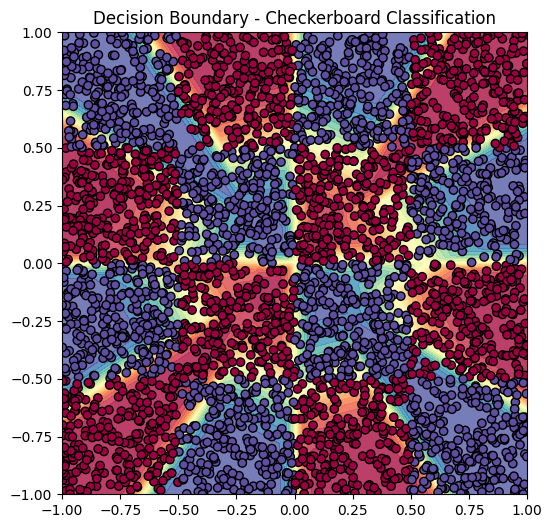

In [13]:
## Run Training
# 2 x 2 k=1, sample size = 3000
# 4 x 4 k=2, sample size = 4000
X, y = generate_data(n_samples=4000, k=2)

# 2 x 2 hidden=64, lr=0.1, epochs=30000
# 4 x 4 hidden=64, lr=0.1, epochs=40000
model = train(X, y, hidden_size=64, lr=0.1, epochs=40000)
plot_decision_boundary(X, y, model)
